This notebook was written by Austin Lopez

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import figurefirst as fifi
from IPython.display import display,SVG
import os
import scipy.signal as signal
import scipy.fft
import copy
import fly_plot_lib.plot as fpl

In [2]:
pwd

'/Users/jaleesahoule/Desktop/SPLITFLOW/final_split_flow_gitrepo/SplitFlowOptoTracking_new/FigureGeneration/Main/fig_2_wind_tunnel_CFD'

In [ ]:
# Data from Dryad (wind_tunnel_data.zip), unzipped into Data/ at the repo root.
WIND_DIR = '../../../Data/wind_tunnel_data'

# Loading all the 10 hz data collected in wind tunnel

* df_0 - df_100 is laminar data
* df_H_xx is the sensor in the horizontal split conditon
* df_V_xx is the sensor in the vertical split conditon
* xx name convention is by location in the wind tunnel data was collected

|    |    |    |
|----|----|----|
| RB | RC | RF |
| MB | MC | MF |
| LB | LC | LF |



In [ ]:
# load wind tunnel data (10 Hz). Figure 2 uses the 40 cm/s laminar recording and the
# two centre positions (left / right) of the horizontal split-flow condition.
DATA_FILES = {
    'df_40':   os.path.join(WIND_DIR, 'laminar_flow', 'laminar_40.csv'),
    'df_H_RC': os.path.join(WIND_DIR, '10_hz_splitflowdata', 'H_RC.csv'),
    'df_H_LC': os.path.join(WIND_DIR, '10_hz_splitflowdata', 'H_LC.csv'),
    'df_TNF':  os.path.join(WIND_DIR, 'outdoor_data', 'df_TNF.csv'),
}
missing = [p for p in DATA_FILES.values() if not os.path.exists(p)]
assert not missing, 'Missing wind tunnel data (download wind_tunnel_data.zip from Dryad):\n' + '\n'.join(missing)

df_40   = pd.read_csv(DATA_FILES['df_40'])
df_H_RC = pd.read_csv(DATA_FILES['df_H_RC'])
df_H_LC = pd.read_csv(DATA_FILES['df_H_LC'])

print(df_40.columns)

## Column titles should be 'time', 'xy_X', 'xy_Y', 'xz_X', 'xz_Z'

##### time is every 1/10th of a second

##### xy_X = X component of the wind with the senor in the xy orientation 

##### xy_Y = Y component of the wind with the senor in the xy orientation 

##### xz_X = X component of the wind with the senor in the xz orientation 

##### xz_Z = Z component of the wind with the senor in the xz orientation 

In [ ]:
# load outdoor data
df_TNF = pd.read_csv(DATA_FILES['df_TNF'])

# function that inputs speed and direction and gets out velocity components x y and tacks it on to the data frame
def wind_components_H(df):
    df['Vx_H'] = -1*df['S2_7'].values*np.cos(np.radians(df['D_7'].values))
    df['Vy_H'] = -1*df['S2_7'].values*np.sin(np.radians(df['D_7'].values))
    return df

def wind_components_V(df):
    df['Vx_V'] = -1*df['S2_8_verticallyorientated'].values*np.cos(np.radians(df['D_8_verticallyorientated'].values))
    df['Vy_V'] = -1*df['S2_8_verticallyorientated'].values*np.sin(np.radians(df['D_8_verticallyorientated'].values))
    return df

df_TNF = wind_components_H(df_TNF)
df_TNF = wind_components_V(df_TNF)

df_TNF.columns

In [170]:
print('Forest data is ' + str(len(df_TNF)/10.) + ' sec long' )

Forest data is 14942.6 sec long


In [171]:
14942.6/3600.

4.150722222222222

# Helper functions

In [172]:
def find_variance_intervals(df, column_low_var, column_high_var, interval_seconds, frequency):
    # Calculate the number of data points in one interval
    points_per_interval = int(interval_seconds / frequency)
    
    # Initialize variables to keep track of the best interval found
    best_interval_start = None
    best_interval_end = None
    min_variance = float('inf')
    max_variance = float('-inf')

    # Sliding window approach to check every n-second interval
    for start_idx in range(len(df) - points_per_interval + 1):
        end_idx = start_idx + points_per_interval
        
        # Get the current interval
        interval_df = df.iloc[start_idx:end_idx]
        
        # Calculate variances
        variance_low_var = interval_df[column_low_var].var()
        variance_high_var = interval_df[column_high_var].var()
        
        # Check if this interval meets the criteria
        if variance_low_var < min_variance and variance_high_var > max_variance:
            min_variance = variance_low_var
            max_variance = variance_high_var
            best_interval_start = start_idx
            best_interval_end = end_idx

    return best_interval_start, best_interval_end

In [173]:
def wrapped_angular_difference(a, b):
    return np.arctan2(np.sin(a-b), np.cos(a-b))

def wrap_angle(a):
    return np.arctan2(np.sin(a), np.cos(a))

def mean_angle(angle):
    return np.arctan2(np.nanmean(np.sin(angle)), np.nanmean(np.cos(angle)))

# Define high-pass filter
def high_pass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='high', analog=False)
    y = signal.filtfilt(b, a, data)
    return y

def calc_filtered_angles(df_TNF, angle_key):

    lastframe = len(df_TNF)-1
    TNF_angdiff = wrapped_angular_difference(df_TNF[angle_key][1:lastframe+1].values, 
                                             df_TNF[angle_key][0:lastframe].values)
    
    fs = 10  # Sampling frequency (Hz), adjust as per your data
    time_constant = 30 # seconds
    cutoff = 1 / (2*time_constant)  # Cutoff frequency (1 / 30 seconds)

    TNF_angdiff_highpassed = high_pass_filter(TNF_angdiff, cutoff, fs)

    y = wrap_angle(np.cumsum(TNF_angdiff_highpassed) )

    y = wrap_angle(y - mean_angle(y))
    
    y = np.hstack([y[0], y])
    
    #return y
    df_TNF['filtered_' + angle_key] = y

In [174]:
# function to get the angle and magnitude from x and y velocity components inputs should be the data frame and the column names of the x and y velocity components save the angle and magnitude to the data frame
def angle_magnitude_XY(df, x, y):
    df['angle_XY'] = np.arctan2(df[y],df[x])
    df['magnitude_XY'] = np.sqrt(df[x]**2 + df[y]**2)
    calc_filtered_angles(df, 'angle_XY')
    return df

def angle_magnitude_XZ(df, x, y):
    df['angle_XZ'] = np.arctan2(df[y],df[x])
    df['magnitude_XZ'] = np.sqrt(df[x]**2 + df[y]**2)
    return df

# Calculate angles and magnitudes

In [ ]:
# make xz_Z negative for the split-flow recordings
df_H_LC['xz_Z'] = -1*df_H_LC['xz_Z']
df_H_RC['xz_Z'] = -1*df_H_RC['xz_Z']

In [ ]:
# get the angle and magnitude of the horizontal velocity components and vertical velocity components
df_40 = angle_magnitude_XY(df_40, 'xy_X', 'xy_Y')
df_40 = angle_magnitude_XZ(df_40, 'xz_X', 'xz_Z')
df_H_LC = angle_magnitude_XY(df_H_LC, 'xy_X', 'xy_Y')
df_H_LC = angle_magnitude_XZ(df_H_LC, 'xz_X', 'xz_Z')
df_H_RC = angle_magnitude_XY(df_H_RC, 'xy_X', 'xy_Y')
df_H_RC = angle_magnitude_XZ(df_H_RC, 'xz_X', 'xz_Z')
df_TNF = angle_magnitude_XY(df_TNF, 'Vx_H', 'Vy_H')
df_TNF = angle_magnitude_XZ(df_TNF, 'Vx_V', 'Vy_V')

In [177]:
df_TNF

,Unnamed: 0,TIME,S2_7,D_7,S2_8_verticallyorientated,D_8_verticallyorientated,Vx_H,Vy_H,Vx_V,Vy_V,angle_XY,magnitude_XY,filtered_angle_XY,angle_XZ,magnitude_XZ
0,0,0.0,0.72,67.0,0.24,259.0,-0.281326,-0.662763,0.045794,0.235591,-1.972222,0.72,-0.748394,1.378810,0.24
1,1,0.1,0.72,67.0,0.24,259.0,-0.281326,-0.662763,0.045794,0.235591,-1.972222,0.72,-0.748394,1.378810,0.24
2,2,0.2,0.60,53.0,0.57,286.0,-0.361089,-0.479181,-0.157113,0.547919,-2.216568,0.60,-1.153098,1.850049,0.57
3,3,0.3,0.94,73.0,0.17,196.0,-0.274829,-0.898926,0.163414,0.046858,-1.867502,0.94,-0.962838,0.279253,0.17
4,4,0.4,0.49,58.0,0.23,193.0,-0.259660,-0.415544,0.224105,0.051739,-2.129302,0.49,-1.381894,0.226893,0.23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149421,149421,14942.1,0.72,144.0,0.77,84.0,0.582492,-0.423205,-0.080487,-0.765782,-0.628319,0.72,2.188895,-1.675516,0.77
149422,149422,14942.2,0.82,144.0,0.73,94.0,0.663394,-0.481984,0.050922,-0.728222,-0.628319,0.82,2.154430,-1.500983,0.73
149423,149423,14942.3,0.71,145.0,0.86,96.0,0.581598,-0.407239,0.089894,-0.855289,-0.610865,0.71,2.134667,-1.466077,0.86
149424,149424,14942.4,0.81,148.0,0.76,96.0,0.686919,-0.429235,0.079442,-0.755837,-0.558505,0.81,2.147003,-1.466077,0.76


# getting TI and STDV

In [220]:
import pandas as pd
import numpy as np
from scipy.stats import circstd
import math

from numpy import (isscalar, r_, log, around, unique, asarray, zeros,
                   arange, sort, amin, amax, atleast_1d, sqrt, array,
                   compress, pi, exp, ravel, count_nonzero, sin, cos,
                   arctan2, hypot)


def _circfuncs_common(samples, high, low, nan_policy='propagate'):
    # Ensure samples are array-like and size is not zero
    samples = np.asarray(samples)
    if samples.size == 0:
        return np.nan, np.asarray(np.nan), np.asarray(np.nan), None

    # Recast samples as radians that range between 0 and 2 pi and calculate
    # the sine and cosine
    sin_samp = sin((samples - low)*2.*pi / (high - low))
    cos_samp = cos((samples - low)*2.*pi / (high - low))
    #sin_samp=sin(samples)
    #cos_samp=cos(samples)
    mask = None
    return samples, sin_samp, cos_samp, mask

def mycircstd(samples, high=360, low=0, axis=None, nan_policy='omit'):

    samples, sin_samp, cos_samp, mask = _circfuncs_common(samples, high, low,
                                                          nan_policy=nan_policy)
    if mask is None:
        sin_mean = sin_samp.mean(axis=axis)  # [1] (2.2.3)
        cos_mean = cos_samp.mean(axis=axis)  # [1] (2.2.3)
    else:
        nsum = np.asarray(np.sum(~mask, axis=axis).astype(float))
        nsum[nsum == 0] = np.nan
        sin_mean = sin_samp.sum(axis=axis) / nsum
        cos_mean = cos_samp.sum(axis=axis) / nsum
    # hypot can go slightly above 1 due to rounding errors
    with np.errstate(invalid='ignore'):
        R = np.minimum(1, hypot(sin_mean, cos_mean))  # [1] (2.2.4)
    res = np.sqrt(2 * (1 -R))
    
    return res*180/np.pi

# function that take in the data frame, and window size in seconds and returns TI for magnitude_XY and STDV of filtered_angle_XY in degrees
def get_TI_STDV(df, window_size,total_time):
    if 'time' in df.columns:
        # Filter the DataFrame based on the 'TIME' column
        df1 = df[df['time'] < total_time]
        TI_data=np.array(df1['magnitude_XY'])
        STDV_data=np.array(df1['angle_XY'])
        time = df1['time']
    # Filter the DataFrame based on the 'TIME' column
    else:
        df1 = df[df['TIME'] < total_time]
        TI_data=np.array(df1['magnitude_XY'])
        STDV_data=np.array(df1['filtered_angle_XY'])
        time = df1['TIME']

    # Replace NaN values with the median of the data
    # TI_data = pd.Series(TI_data).fillna(pd.Series(TI_data).median()).to_numpy()
    # STDV_data = pd.Series(STDV_data).fillna(pd.Series(STDV_data).median()).to_numpy()

    # chunck data into windows of size window_size
    # wind size is in seconds and sample rate is 10 Hz so should be chuncks of 10hz times window size
    num_windows = int(total_time/window_size)
    TI=[]
    STDV=[]
    for i in range(num_windows):
        start = i*window_size*10
        end = (i+1)*window_size*10
        
        TI.append(np.nanstd(TI_data[start:end])/np.nanmean(TI_data[start:end]))
        # np.degrees(mycircstd(np.degrees(STDV_data[start:end]), high=180, low=-180))

        # STDV.append(np.nanstd(STDV_data[start:end])*180/np.pi)
        STDV.append(mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360))

        # plt.plot(np.degrees(STDV_data[start:end]),color='black')
        # plt.plot(np.degrees(STDV_data[start:end]) + mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360)*3,color='red')
        # plt.plot(np.degrees(STDV_data[start:end]) - mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360)*3,color='red')
        # plt.title('Window ' + str(i)+ '\n Time: ' + str(time[start]) + ' to ' + str(time[end-1]) + '\n STDV: ' + str(mycircstd(np.degrees(STDV_data[start:end-1]), high=180, low=-180)))
        # plt.show()

    # add nan to the end of the data to make it the same size as the original data
    TIsize = len(df) - len(TI)
    STDVsize = len(df) - len(STDV)
    TI = np.append(TI, np.zeros(TIsize)*np.nan)
    STDV = np.append(STDV, np.zeros(STDVsize)*np.nan)

    df['TI'] = TI
    df['STDV'] = STDV

    return df
    

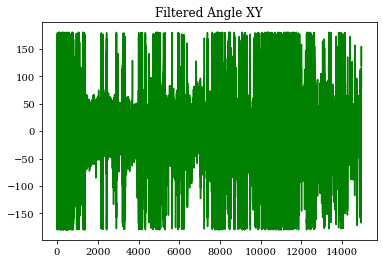

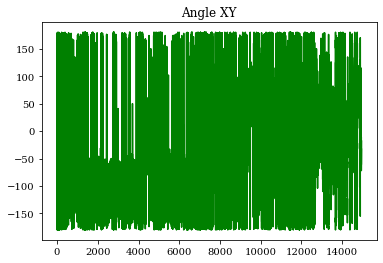

In [221]:
# plt.plot(df_H_RC['filtered_angle_XY'])
# plt.show()

# plt.plot(df_H_RC['filtered_angle_XY'][0:100])
# plt.show()

sub_data=df_TNF['filtered_angle_XY'].copy()

# for i in range(len(sub_data)):
#     if sub_data[i] < 2:
#         sub_data[i] = sub_data[i] + 2*np.pi

plt.plot(df_TNF['TIME'],np.degrees(sub_data),color='green')
plt.title('Filtered Angle XY')
plt.show()

plt.plot(df_TNF['TIME'],np.degrees(df_TNF['angle_XY']),color='green')
plt.title('Angle XY')
plt.show()

# plt.plot(df_H_RC['filtered_angle_XY'])
# plt.show()

In [ ]:
# get TI and STDV for the data used in the figure
# 10 s windows over the first 150 s (reproduces the published panels C and F)
df_40   =get_TI_STDV(df_40  ,10,150)
df_H_LC =get_TI_STDV(df_H_LC,10,150)
df_H_RC =get_TI_STDV(df_H_RC,10,150)
df_TNF  =get_TI_STDV(df_TNF ,10,150)

# Colors

In [230]:
# creat a gradient of colors for the plot make them all shades of oragne
colors = plt.cm.Oranges(np.linspace(0, 1, 10))
# creat a gradient of colors for the plot make them all shades of purple
colors2 = plt.cm.Purples(np.linspace(0, 1, 10))
# creat a gradient of colors for the plot make them all shades of blue
colors3 = plt.cm.Blues(np.linspace(0, 1, 10))

color_black = 'black'
color_green = 'green'
color_orange = colors[6]
color_blue = colors3[6]
color_purple = colors2[6]

In [231]:
# print color code for blue purple and orange
print("color_blue = '" + str(color_blue) + "'")
print("color_purple = '" + str(color_purple) + "'")
print("color_orange = '" + str(color_orange) + "'")

color_blue = '[0.21568627 0.52941176 0.75424837 1.        ]'
color_purple = '[0.47320261 0.43267974 0.69934641 1.        ]'
color_orange = '[0.91372549 0.36862745 0.05098039 1.        ]'


In [ ]:
# Helvetica matches the typography of the published (PNAS) figure.
plt.rcParams['font.family'] = 'Helvetica'
plt.rcParams['text.usetex'] = False
plt.rcParams["ps.usedistiller"] = 'xpdf'
plt.rcParams['font.weight'] = 'normal'
plt.rcParams["mathtext.fontset"] = 'cm'

# start here

In [ ]:
# Figure 2 is built on fig2_template.svg (layout boxes + hand-made artwork).
# This notebook runs first: it starts a fresh copy of the template, then
# fig2_CFD.ipynb adds panel J to the same file.
# The committed, published version is output_figs/fig2_tunnel_methods.svg.
import shutil
TEMPLATE_SVG = 'fig2_template.svg'
input_svg = 'fig2_tunnel_methods.svg'
shutil.copy(TEMPLATE_SVG, input_svg)
layout = fifi.svg_to_axes.FigureLayout(input_svg, autogenlayers=True, make_mplfigures=True, hide_layers=[])

# All Time series plots

In [ ]:
if 0:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('wind_speed', 'A')]

ax.plot(df_40['time'], df_40['magnitude_XY'], color='black', alpha=1, zorder=-1, linewidth=1)
ax.plot(df_TNF['TIME'], df_TNF['magnitude_XY'], color=color_green, alpha=1, zorder=-1, linewidth=1)

# ax.set_xticks([20, 25, 30, 35, 40])
# ax.set_xlim([20,40])
# ax.set_xticklabels([])  # '0', '$-\pi/4$', '$-\pi/2$', '$-3\pi/4$', '$\pm\pi$', '$3\pi/4$', '$\pi/2$', '$\pi/4$']

# # Set the yticks off
# ax.set_yticks([0, .5, 1, 1.5])
# ax.set_ylim([0,1.5])
# # ax.set_yticklabels([])

############
ax.set_xlim([20,40])
ax.set_ylim(0,1.5)
fifi.mpl_functions.adjust_spines(ax, ['left','bottom'], yticks =[0,0.5,1,1.5], xticks=[20, 25, 30, 35, 40],
                                   tick_length=3, linewidth=0.75,spine_locations={'left': 5, 'bottom': 5})
ax.set_yticklabels(['0', '', '', '1.5'])
ax.set_xticklabels(['5', '', '', '', '25'])
ax.set_aspect('equal')
# ax.set_rasterized(True)
ax.set_ylabel('Wind speed\n(m/s)', labelpad=1.45)
ax.set_xlabel('Time (s)', labelpad=-4.6)
ax.tick_params(pad=0.7)
fifi.mpl_functions.set_fontsize(ax, 6)
############

# ax.set_rasterization_zorder(0)

if 0:
    plt.show()
    fig.savefig('indoor_wind_speed.pdf', dpi=300)

In [ ]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('wind_speed', 'B')]

ax.plot(df_H_RC['time'], df_H_RC['magnitude_XY'], color=color_orange, alpha=1, zorder=-1, linewidth=1)
# ax.plot(df_H_MC['time'], df_H_MC['magnitude_XY'], color=color_purple, alpha=1, zorder=-1)
ax.plot(df_H_LC['time'], df_H_LC['magnitude_XY'], color=color_blue, alpha=1, zorder=-1, linewidth=1)

# ax.set_xticks([20, 25, 30, 35, 40])

# ax.set_xticklabels(['5', '', '', '', '25'])  # '0', '$-\pi/4$', '$-\pi/2$', '$-3\pi/4$', '$\pm\pi$', '$3\pi/4$', '$\pi/2$', '$\pi/4$']

# # Set the yticks off
# ax.set_yticks([0, .5, 1, 1.5])
# ax.set_ylim([0,1.5])
# # ax.set_yticklabels([])

############
ax.set_xlim([20,40])
ax.set_ylim(0,1.5)
fifi.mpl_functions.adjust_spines(ax, ['left','bottom'], yticks =[0,0.5,1,1.5], xticks=[20, 25, 30, 35, 40],
                                   tick_length=3, linewidth=0.75,spine_locations={'left': 5, 'bottom': 5})
ax.set_yticklabels(['0', '', '', '1.5'])
ax.set_xticklabels(['5', '', '', '', '25'])
ax.set_aspect('equal')
# ax.set_rasterized(True)
ax.set_ylabel('Wind speed\n(m/s)', labelpad=1.45)
ax.set_xlabel('Time (s)', labelpad=-4.6)
ax.tick_params(pad=0.7)
fifi.mpl_functions.set_fontsize(ax, 6)
############
# ax.set_rasterization_zorder(0)

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['wind_speed'], 'wind_speed', cleartarget=True)
layout.write_svg(input_svg)

# All STDV and TI

In [ ]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('TI_vs_S', 'A')]

ax.scatter(df_40['STDV'], df_40['TI'], s=13.5, linewidths=0.82, color='black',alpha=.5, clip_on=False)
ax.scatter(df_TNF['STDV'], df_TNF['TI'], s=13.5, linewidths=0.82, color=color_green,alpha=.5, clip_on=False)


############
# marker size matches the published figure; clip_on=False keeps points at x~0 whole
ax.set_xlim(0,95)
ax.set_ylim(0,.85)
fifi.mpl_functions.adjust_spines(ax, ['left','bottom'], yticks =[0,.2,.4,.6,.8], xticks=[0,30,60,90],
                                  spine_locations={'left': 3, 'bottom': 4}, tick_length=3, linewidth=0.75)

ax.set_ylabel('Turbulence intensity', labelpad=1.9)
ax.set_xlabel('Standard deviation in\ndirection (°)', labelpad=1.5, linespacing=0.9)
ax.tick_params(pad=1.75)
fifi.mpl_functions.set_fontsize(ax, 6)
############
ax.set_rasterization_zorder(0)

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('TI_vs_S', 'B')]

# ax.scatter(df_40['STDV'], df_40['TI'], s=20, color='black')
# ax.scatter(df_TNF['STDV'], df_TNF['TI'], s=20, color=color_green)
ax.scatter(df_H_LC['STDV'], df_H_LC['TI'], s=13.5, linewidths=0.82, color=color_blue,alpha=.5, clip_on=False)
# ax.scatter(df_H_MC['STDV'], df_H_MC['TI'], s=20, color=color_purple)
ax.scatter(df_H_RC['STDV'], df_H_RC['TI'], s=13.5, linewidths=0.82, color=color_orange,alpha=.5, clip_on=False)


############
# marker size matches the published figure; clip_on=False keeps points at x~0 whole
ax.set_xlim(0,95)
ax.set_ylim(0,.85)
fifi.mpl_functions.adjust_spines(ax, ['left','bottom'], yticks =[0,.2,.4,.6,.8], xticks=[0,30,60,90],
                                  spine_locations={'left': 3, 'bottom': 4}, tick_length=3, linewidth=0.75)

ax.set_ylabel('Turbulence intensity', labelpad=1.9)
ax.set_xlabel('Standard deviation in\ndirection (°)', labelpad=1.5, linespacing=0.9)
ax.tick_params(pad=1.75)
fifi.mpl_functions.set_fontsize(ax, 6)
############
ax.set_rasterization_zorder(0)

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['TI_vs_S'], 'TI_vs_S', cleartarget=True)
layout.write_svg(input_svg)

# Steady smoke pics

In [ ]:
# function to grayscale an inputed image
def grayscale_image(image):
    return np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

# import images from still_images/
# save all images in directory still_images/ to a dictionary
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# path to the directory containing the images
path = 'smokepen_images/'
# create an empty dictionary to store the images
images = {}
# loop through all the files in the directory
for filename in os.listdir(path):
    # check if the file is an image
    if filename.endswith('.jpg'):
        # read the image and store it in the dictionary
        images[filename] = mpimg.imread(os.path.join(path, filename))
# print the keys of the dictionary alpphabetically
print(sorted(images.keys()))
# print pixel dimensions of the first image x and y 
print('image x dimension:', images['steady_left_02_cal_rot_t=5.6s.jpg'].shape[0])

# display image and display fliped up image
# plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
# plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])

# 6 by 2 grid of images
# fig, axs = plt.subplots(6, 2, figsize=(2, 16))
# list of images to display
images_to_display = ['steady_left_02_cal_rot_t=5.6s.jpg', 'steady_bottom_01_cal_rot_t=12s.jpg',
                      'unsteady_right_04_cal_rot_t=45s.jpg', 'unsteady_bottom_01_cal_t=2.4s.jpg',
                        'steady_left_02_cal_rot_t=10.6s.jpg', 'unsteady_right_04_cal_rot_t=50s.jpg',
                          'unsteady_bottom_01_cal_t=7.8s.jpg', 'unsteady_right_04_cal_rot_t=40s.jpg',
                            'steady_bottom_01_cal_rot_t=2s.jpg', 'unsteady_bottom_01_cal_t=12.8s.jpg',
                              'steady_left_02_cal_rot_t=15.6s.jpg', 'steady_bottom_01_cal_rot_t=7s.jpg']
# loop through the images and display them
# for i, ax in enumerate(axs.flat):
#     ax.imshow(images[images_to_display[i]])
#     ax.axis('off')
#     # ax.set_xlim(700, 1200)
#     ax.set_ylim(700,1500)
# adjust the layout
# plt.subplots_adjust(wspace=0, hspace=0)
# save the figure
# plt.savefig('still_images/all_images.jpg', dpi=300, bbox_inches='tight')
# display the figure
# plt.show()

In [777]:
# print dimention of the first image
print(images['steady_left_02_cal_rot_t=5.6s.jpg'].shape)

(1920, 1200, 3)


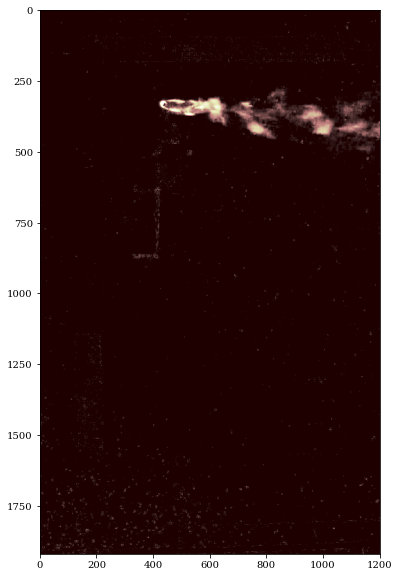

In [778]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'images' is a dictionary containing your images
image = images['steady_left_02_cal_rot_t=5.6s.jpg']

# Convert the RGB image to grayscale
gray_image = np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

# Flip the grayscale image vertically
flipped_image = np.flip(gray_image, axis=0)

# Create a new figure and axis
fig, ax = plt.subplots(figsize=(10, 10))  # Adjust the figsize as needed

# Plot the flipped grayscale image using cmap 'pink'
ax.imshow(flipped_image, cmap='pink', aspect='auto')

# Set the x and y limits
ax.set_xlim([0, 1200])
ax.set_ylim([1920, 0])  # Inverted y-axis

# Set the aspect ratio to be equal
ax.set_aspect('equal')

plt.show()

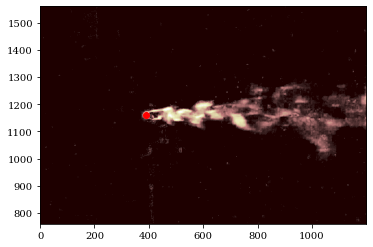

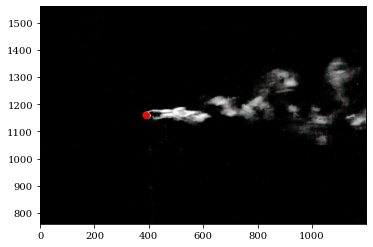

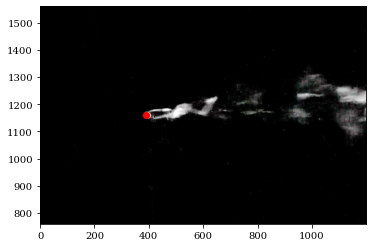

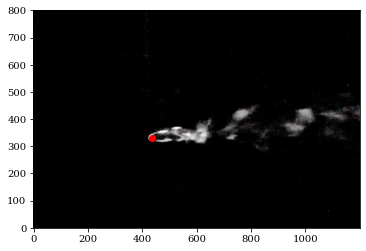

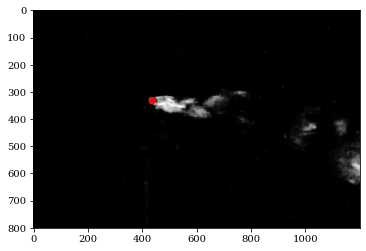

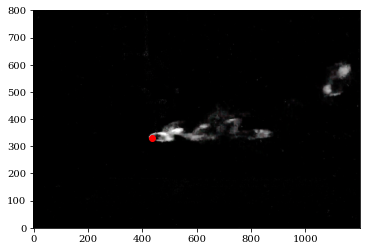

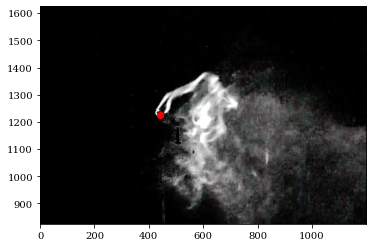

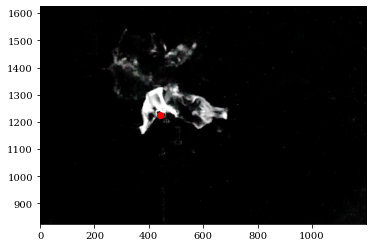

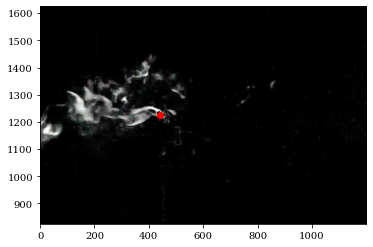

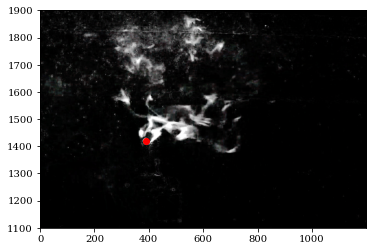

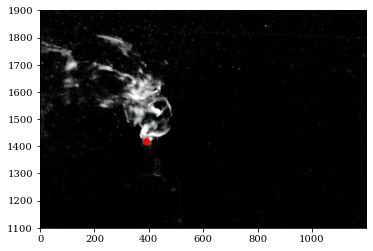

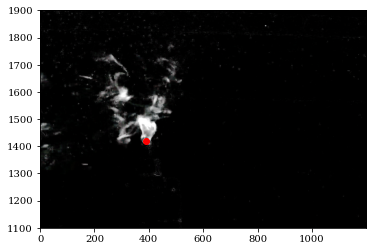

In [780]:
# plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
# plt.show()
# plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])
# plt.show()
# plot all images individually and have y limit
plt.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=2s.jpg']),cmap='pink')
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_bottom_01_cal_rot_t=7s.jpg'])
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_bottom_01_cal_rot_t=12s.jpg'])
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])
plt.ylim(0,800)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=10.6s.jpg'][::-1])
plt.ylim(800,0)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=15.6s.jpg'][::-1])
plt.ylim(0,800)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=2.4s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=7.8s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=40s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=45s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=50s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()


In [788]:
# print the keys in the dictionary
print(images.keys())

dict_keys(['steady_left_02_cal_rot_t=5.6s.jpg', 'steady_bottom_01_cal_rot_t=12s.jpg', 'unsteady_right_04_cal_rot_t=45s.jpg', 'unsteady_bottom_01_cal_t=2.4s.jpg', 'steady_left_02_cal_rot_t=10.6s.jpg', 'unsteady_right_04_cal_rot_t=50s.jpg', 'unsteady_bottom_01_cal_t=7.8s.jpg', 'unsteady_right_04_cal_rot_t=40s.jpg', 'steady_bottom_01_cal_rot_t=2s.jpg', 'unsteady_bottom_01_cal_t=12.8s.jpg', 'steady_left_02_cal_rot_t=15.6s.jpg', 'steady_bottom_01_cal_rot_t=7s.jpg'])


# Unsteady smoke pictures

# Steady_zoom pics

In [796]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'A')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=2s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1560,760])
#add red dot at x=390, y=1160
ax.scatter([390], [1160], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [798]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'C')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=12s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1560,760])
#add red dot at x=390, y=1160
ax.scatter([390], [1160], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['stead_smoke_zoom'], 'stead_smoke_zoom', cleartarget=True)
layout.write_svg(input_svg)

# Unsteady_Zoom pics

In [803]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'A')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_bottom_01_cal_t=2.4s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1625,825])
#add red dot at (440,1225)
ax.scatter([440], [1225], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [805]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'C')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_bottom_01_cal_t=12.8s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1625,825])
#add red dot at (440,1225)
ax.scatter([440], [1225], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['unstead_smoke_zoom'], 'unstead_smoke_zoom', cleartarget=True)
layout.write_svg(input_svg)